# APA of in-situ-defined differential loops on the sc pseudobulk

**Plotting notebook.** The expensive pile-up already ran (`step08_apa_insitu_defined.py`) and
its arrays are cached in an `.npz`, so every cell below is fast. Set `RECOMPUTE = True` in the
load cell to redo the pile-up from the `.Q.cool` files (~45 s).

## Which loop set (`LOOPSET` in section 1)

Both are defined by the in-situ Hi-C and never see the sc data. They differ in how
"differential" is decided:

| `LOOPSET` | how | n (GM / IMR) | a real test? |
|---|---|---|---|
| `hiccupsdiff` **(default)** | juicer `hiccupsdiff` -- tests contact frequency at each loop directly, with FDR | 516 / 968 | yes |
| `setdiff` | `scripts/diff_loops.py` -- presence/absence across the two HICCUPS call sets (L_inf, 25 kb) | 2,434 / 5,401 | no, threshold cliff |

`hiccupsdiff` is the only definition that is **both** a real statistical test and independent
of the sc data. Set-difference is independent but not a test; the sc ANOVA in
`loop_insitu_apa.ipynb` is a test but circular.

## What makes this different from `loop_insitu_apa.ipynb`

`loop_insitu_apa.ipynb` cell 54 selects differential loops from `loopq`/`loopt` -- statistics
derived from the sc-imputed Q/T matrices -- and then piles up O/E from **those same Q
matrices**. Selection and display share the underlying data, so the clean diagonal is partly
guaranteed by winner's curse (double-dipping). That design is inherited from the scHiCluster
HBA tutorial, where it is legitimate: there was no independent deep Hi-C, so the APA panel is
a *display of* the ANOVA result, not evidence for it.

Here the loop sets come **entirely from the ENCODE in-situ Hi-C** -- either
`step10_hiccupsdiff.sbatch` or `step07_diff_loops_gpfs.sh`, per `LOOPSET` above. The selection
never sees the sc data, so it can only attenuate a real effect, never manufacture one: a
surviving signal is evidence rather than a restatement of the selection.

## The two renderings

Both are computed from the same pile-up; they differ only in how each loop window is stacked.

| | what it does | what it measures |
|---|---|---|
| **min-max** | rescales each 17x17 window to [0,1] on its own min/max *before* averaging | how **consistently present** the loops are (focality). Amplitude is erased -- a 20x loop and a 1.4x loop both contribute a 1.0 at the centre, so it is robust to the outlier problem below. |
| **raw** | averages the actual O/E values | how **strong** the loops are (juicer P2LL convention) |

Every panel is titled with **both** scores so the two are never confused.

**The final figure is section 5** -- the difference map. The 2xN grids in section 4
are diagnostics; section 5 is the one that carries the specificity claim, because it
divides the two pseudobulks rather than asking the eye to compare across rows.

Reference: [scHiCluster HBA 03.apa](https://zhoujt1994.github.io/scHiCluster/hba/loop_majortype/03.apa.html)

## 1. Setup

In [1]:
%matplotlib inline
import os
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

BASE = "/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu"
sys.path.insert(0, BASE)

OUTDIR = f"{BASE}/data/diff/GM12878_IMR90_insitu_loops"
FIGDIR = f"{OUTDIR}/figures"

# ---- which in-situ differential loop definition to plot -------------------------
# "hiccupsdiff" -- juicer hiccupsdiff: tests contact frequency directly, with FDR.
#                  516 / 968 loops. A real test AND independent of the sc data.
# "setdiff"     -- scripts/diff_loops.py: presence/absence in the two HICCUPS call
#                  sets. 2,434 / 5,401 loops. Independent, but not a test.
LOOPSET = "hiccupsdiff"

_CFG = {
    "hiccupsdiff": ("apa_insituHCD.npz", "APA_2xN_insituHCD_diffloops",
                    "juicer hiccupsdiff (FDR-tested)"),
    "setdiff":     ("apa_insituDEF.npz", "APA_2xN_insituDEF_diffloops",
                    "HICCUPS set-difference"),
}
NPZ_NAME, FIG_BASE, LOOPSET_DESC = _CFG[LOOPSET]
NPZ = f"{FIGDIR}/{NPZ_NAME}"

celltypes = ["GM12878", "IMR90"]

res             = 25000
apa_flank_bp    = 200_000
apa_flank_bins  = apa_flank_bp // res          # 8
apa_window_size = 2 * apa_flank_bins + 1       # 17
BG_WIDTH        = max(1, min(5, apa_flank_bins))

# Colour limits for the min-max panel. The scHiCluster tutorial uses 0.2/0.8, but these
# data only span ~0.20-0.47, so 0.8 wastes more than half the colour range and every panel
# reads as pale yellow. 0.5 uses the full ramp. The cell below reports any clipping --
# hiccupsdiff clips nothing (max 0.474); setdiff peaks at 0.543 and would clip ~0.8% of
# pixels, so raise VMAX_MM to 0.55 if you switch LOOPSET.
VMIN_MM, VMAX_MM = 0.2, 0.5

# Per-panel score titles. False gives bare panels for a publication figure --
# the numbers are still printed as tables in section 3 and written to the
# stats .tsv in section 7.
SHOW_PANEL_SCORES = False

# Gap between panels, as a fraction of panel size. These were sized to fit the
# two-line score titles; with SHOW_PANEL_SCORES = False they can be much tighter.
# Raise them if you turn the titles back on.
PANEL_WSPACE, PANEL_HSPACE = 0.10, 0.10

# Arial + editable text in Illustrator, matching the rest of the figure set
mpl.rcParams["font.family"]     = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial", "Liberation Sans", "DejaVu Sans"]
mpl.rcParams["pdf.fonttype"]    = 42
mpl.rcParams["ps.fonttype"]     = 42

print(f"LOOPSET = {LOOPSET}  ({LOOPSET_DESC})")
print(f"window {apa_window_size}x{apa_window_size} "
      f"(+/-{apa_flank_bp//1000} kb at {res//1000} kb), corner background {BG_WIDTH}x{BG_WIDTH}")

LOOPSET = hiccupsdiff  (juicer hiccupsdiff (FDR-tested))
window 17x17 (+/-200 kb at 25 kb), corner background 5x5


## 2. Load the pile-up

Default is to read the cached arrays. Flip `RECOMPUTE` to re-run the pile-up itself --
it reuses `apa()` from `step08_apa_insitu_defined.py`, so there is only one copy of that
code. Note the recompute iterates **all 22 autosomes**; `loop_insitu_apa.ipynb` cell 54 uses
`chrom_sizes.index[:-1]`, which silently drops chr22 because the sizes file is autosomes-only
(in the scHiCluster reference that slice legitimately dropped a sex chromosome).

In [2]:
RECOMPUTE = False   # True -> redo the pile-up from the .Q.cool files (~45 s, 2 workers)

if RECOMPUTE:
    os.environ["APA_LOOPSET"] = LOOPSET   # step08 reads this at import time
    import cooler
    from concurrent.futures import ProcessPoolExecutor, as_completed
    import step08_apa_insitu_defined as s8

    chrom_sizes = cooler.read_chromsizes(s8.chrom_size_path, all_names=True)
    if not any(str(c).startswith("chr") for c in chrom_sizes.index):
        chrom_sizes.index = ["chr" + str(c) for c in chrom_sizes.index]
    chrom_index = list(chrom_sizes.index)          # all 22 autosomes
    print(f"chromosomes: {len(chrom_index)} ({chrom_index[0]}..{chrom_index[-1]})")

    loop_labels, loop_list = s8.load_loopsets()
    n_rows, n_cols = len(celltypes), len(loop_list)

    vis_all = np.full((n_rows, n_cols, apa_window_size, apa_window_size), np.nan)
    raw_all = np.full_like(vis_all, np.nan)
    cnt_all = np.zeros((n_rows, n_cols), dtype=np.int64)
    centres, wins_all = {}, {}

    with ProcessPoolExecutor(max_workers=2) as ex:
        futs = {ex.submit(s8.apa, ct, s8.indir, chrom_index, loop_list,
                          res, s8.dist, apa_flank_bins): i
                for i, ct in enumerate(celltypes)}
        for fut in as_completed(futs):
            i = futs[fut]
            v, r, c, ctr, wins = fut.result()
            vis_all[i], raw_all[i], cnt_all[i] = v, r, c
            centres[celltypes[i]] = ctr
            wins_all[celltypes[i]] = wins
            print(f"  {celltypes[i]} finished")

    diffmap = np.full((n_cols, apa_window_size, apa_window_size), np.nan)
    for j in range(n_cols):
        with np.errstate(divide="ignore", invalid="ignore"):
            lr = np.log2(wins_all["GM12878"][j] / wins_all["IMR90"][j])
        lr[~np.isfinite(lr)] = np.nan
        if np.any(np.isfinite(lr)):
            diffmap[j] = np.nanmedian(lr, axis=0)
else:
    z = np.load(NPZ, allow_pickle=False)
    vis_all = z["vis_all"]
    raw_all = z["raw_all"]
    cnt_all = z["cnt_all"]
    diffmap = z["diffmap"]
    loop_labels = [str(s) for s in z["loop_labels"]]
    n_rows, n_cols = vis_all.shape[0], vis_all.shape[1]
    centres = {ct: [z[f"centres_{ct}_{j}"] for j in range(n_cols)] for ct in celltypes}
    print(f"loaded {NPZ}")

print("\nwindows contributing to each panel:")
pd.DataFrame(cnt_all, index=celltypes, columns=loop_labels)

loaded /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/apa_insituHCD.npz

windows contributing to each panel:


,GM12878 specific loops,IMR90 specific loops
GM12878,287,666
IMR90,286,666


## 3. APA scores -- both conventions

Same formula in both cases: centre pixel divided by the mean of the lower-left corner block.
The only difference is which matrix it is applied to.

- **min-max** -- what the scHiCluster tutorial reports (`tmp[10,10]/tmp[-5:, :5].mean()` on the
  rescaled result). Comparable to published numbers.
- **raw** -- the juicer P2LL convention, an actual O/E enrichment.

In [3]:
def apa_score(panel, flank=apa_flank_bins, bg_width=BG_WIDTH):
    '''Centre pixel / mean of the lower-left corner block.'''
    ctr = panel[flank, flank]
    bg = np.mean(panel[-bg_width:, :bg_width])
    if np.isfinite(ctr) and np.isfinite(bg) and bg > 0:
        return ctr / bg
    return np.nan


score_mm = np.array([[apa_score(vis_all[i, j]) for j in range(n_cols)]
                     for i in range(n_rows)])
score_raw = np.array([[apa_score(raw_all[i, j]) for j in range(n_cols)]
                      for i in range(n_rows)])

print("APA on the min-max matrix  (scHiCluster convention; focality)")
display(pd.DataFrame(score_mm, index=celltypes, columns=loop_labels).round(3))

print("\nAPA on raw mean O/E  (juicer P2LL convention; amplitude)")
display(pd.DataFrame(score_raw, index=celltypes, columns=loop_labels).round(3))

APA on the min-max matrix  (scHiCluster convention; focality)


,GM12878 specific loops,IMR90 specific loops
GM12878,1.739,1.360
IMR90,1.316,1.558



APA on raw mean O/E  (juicer P2LL convention; amplitude)


,GM12878 specific loops,IMR90 specific loops
GM12878,4.139,1.875
IMR90,3.860,1.966


## 4. Figures

`draw()` renders whichever matrix you hand it and titles each panel with **both** scores --
the one matching the rendering first, the other in parentheses. Pass `out_base=None` to
preview without writing files.

In [4]:
def draw(panels, primary, secondary, primary_name, secondary_name,
         cbar_label, vmin, vmax, out_base=None):
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(n_cols * 2.4, n_rows * 2.0),
                             sharex=True, sharey=True, dpi=300)
    fig.subplots_adjust(wspace=PANEL_WSPACE, hspace=PANEL_HSPACE)

    for i in range(n_rows):
        for j in range(n_cols):
            ax = axes[i, j]
            im = ax.imshow(panels[i, j], cmap="hot_r", vmin=vmin, vmax=vmax)
            if SHOW_PANEL_SCORES:
                ax.set_title(f"APA ({primary_name}) = {primary[i, j]:.2f}\n"
                             f"{secondary_name} {secondary[i, j]:.2f}",
                             fontsize=7, linespacing=1.3)

    for i, ct in enumerate(celltypes):
        axes[i, 0].set_ylabel(ct)

    for j, lb in enumerate(loop_labels):
        axes[-1, j].set_xlabel(f"{lb}\n(n = {cnt_all[0, j]})", fontsize=8)

    edge = apa_window_size - 1
    lab = f"{apa_flank_bp // 1000}k"
    axes[-1, 0].set_xticks([0, edge])
    axes[-1, 0].set_xticklabels([f"-{lab}", f"+{lab}"])
    axes[-1, 0].set_yticks([0, edge])
    axes[-1, 0].set_yticklabels([f"-{lab}", f"+{lab}"])

    # All panels share axes, so duplicate x labels add nothing and collide at tight
    # PANEL_WSPACE (left '+200k' running into right '-200k'). Keep them on the
    # leftmost panel only.
    for jj in range(1, n_cols):
        axes[-1, jj].tick_params(labelbottom=False)

    # the leftmost xlabel sits below its tick labels, the others do not -- put them
    # all on one baseline
    fig.align_xlabels(axes[-1, :])

    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.046, pad=0.04)
    cbar.set_label(cbar_label, fontsize=7)
    cbar.ax.tick_params(labelsize=6)

    if out_base:
        os.makedirs(FIGDIR, exist_ok=True)
        for ext in ("png", "pdf"):
            p = f"{FIGDIR}/{out_base}.{ext}"
            fig.savefig(p, dpi=300, bbox_inches="tight", transparent=(ext == "pdf"))
            print("saved:", p)
    return fig

### 4a. Min-max rendering

Read this panel **within a row, not across rows.** Comparing left-vs-right inside one row is
valid: GM-specific beats IMR-specific in the GM row, and the reverse in the IMR row -- the
diagonal you want. But the two rows sit at different baselines (panel means 0.338/0.336 for
GM against 0.279/0.291 for IMR), because min-max rescaling depends on the shape of the value
distribution inside each window and that differs between the two pseudobulks. The tighter
colour limits make the focal dots legible but also make that row offset more obvious.

Section 5 is the panel that is immune to it, since it divides the two cell types rather than
asking the eye to compare them.

**Why min-max is nonetheless the more trustworthy of the two renderings here:** the raw
pile-up of the GM-specific set is dominated by a handful of loops -- the top 5% of loops carry
~75% of the total signal, and mean/median is 3.8. Those few loops are strong in *both* cell
types, which is why the raw GM-specific column reads high on both rows. Min-max caps every
loop's contribution at 1.0, making it implicitly rank-like and robust to exactly that.

min-max data range 0.199 - 0.474   colour limits 0.2 - 0.5
clipped: 0 px above VMAX_MM, 1 px below VMIN_MM  (of 1156)
  -> lower VMIN_MM below 0.199 to show the bottom of the range


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops.png


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops.pdf


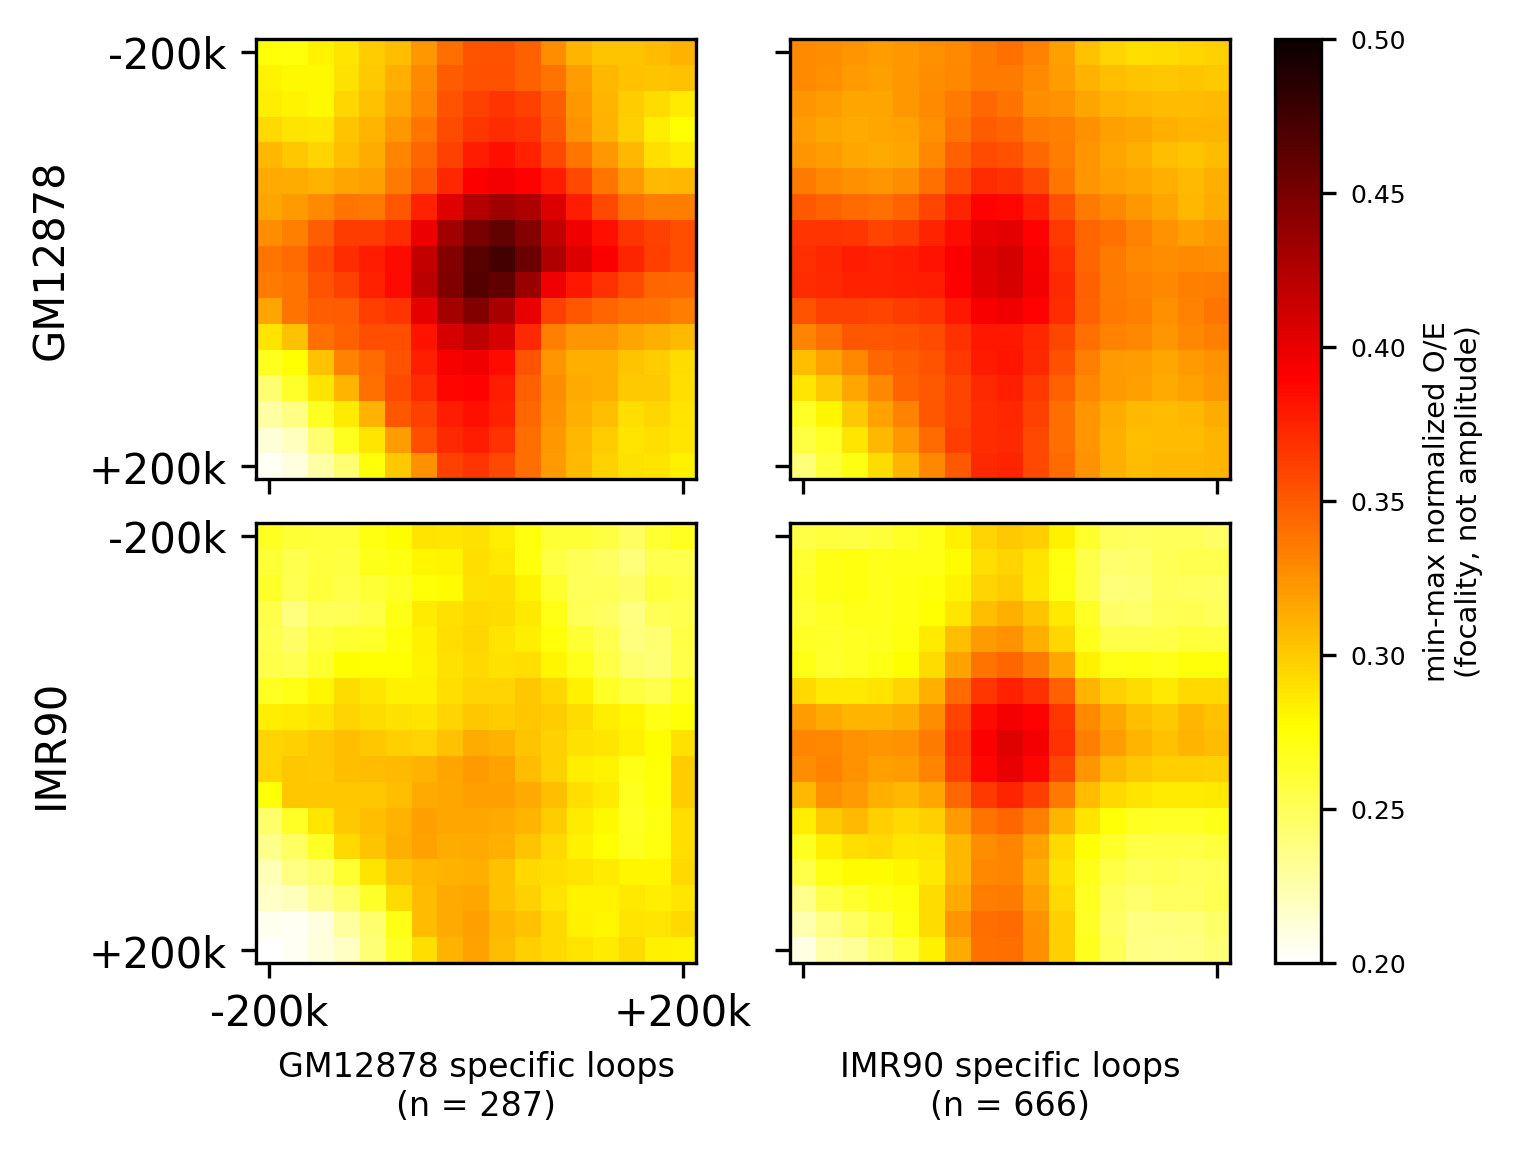

In [5]:
lo, hi = float(np.nanmin(vis_all)), float(np.nanmax(vis_all))
n_hi = int((vis_all > VMAX_MM).sum())
n_lo = int((vis_all < VMIN_MM).sum())
print(f"min-max data range {lo:.3f} - {hi:.3f}   colour limits {VMIN_MM} - {VMAX_MM}")
print(f"clipped: {n_hi} px above VMAX_MM, {n_lo} px below VMIN_MM  "
      f"(of {vis_all.size})")
if n_hi:
    print(f"  -> raise VMAX_MM above {hi:.3f} to show the top of the range")
if n_lo:
    print(f"  -> lower VMIN_MM below {lo:.3f} to show the bottom of the range")
if not (n_hi or n_lo):
    print("  -> nothing clipped")

fig = draw(vis_all, score_mm, score_raw, "min-max", "raw",
           "min-max normalized O/E\n(focality, not amplitude)",
           vmin=VMIN_MM, vmax=VMAX_MM,
           out_base=FIG_BASE)
plt.show()

### 4b. Raw O/E rendering

Absolute pile-up strength -- and the least trustworthy panel here. Two compounding problems:

1. **Outlier domination.** For the GM-specific set the top 5% of loops carry ~75-79% of the
   whole pile-up (mean 6.03 vs median 1.58 in GM; 5.78 vs 1.14 in IMR90). The arithmetic mean
   is showing ~14 loops, not the set, and those loops are strong in both cell types. Hence
   ratio-of-means 1.043x against median-of-ratios 1.413x.
2. **Selection.** GM in-situ was subsampled to p=0.307 *before* HICCUPS, so only the strongest
   GM loops survived calling, and hiccupsdiff then required significance on top. Double-filtered
   into the extreme tail. IMR90 ran at full depth, so its set is broader and more moderate.

Both are properties of the loop set, not biology. Not a distance artefact either: median
separation 625 kb (GM-specific) vs 688 kb (IMR-specific).

saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops_raw.png


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops_raw.pdf


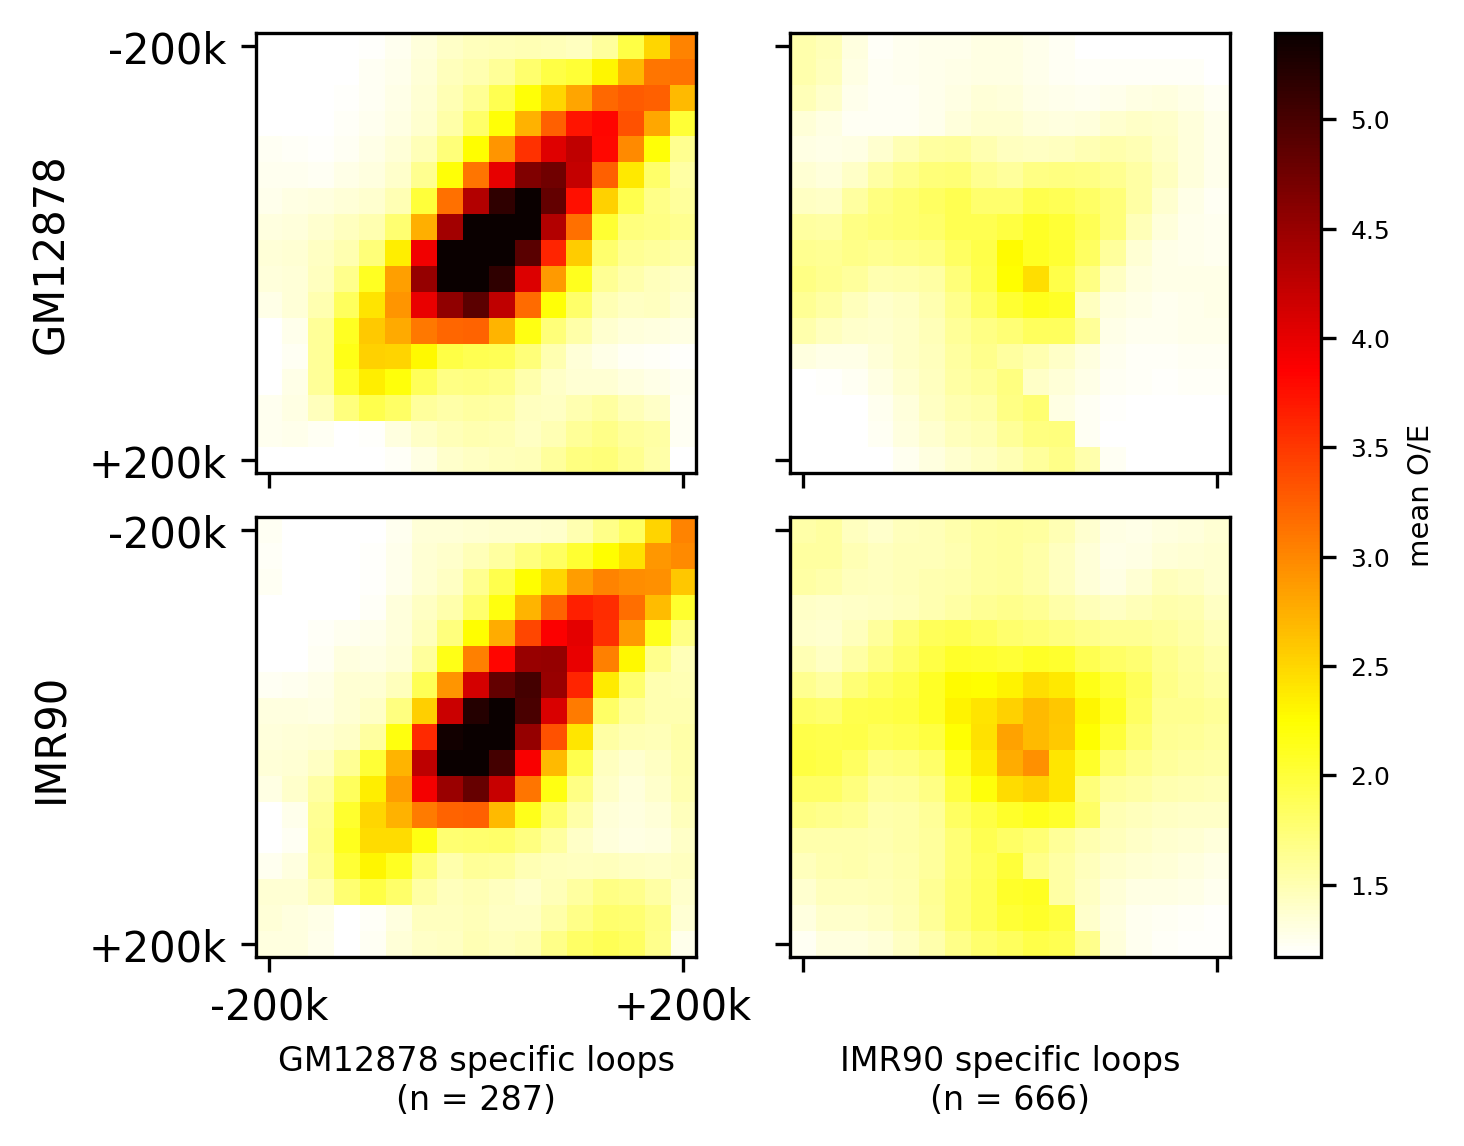

In [6]:
rmin = float(np.nanpercentile(raw_all, 5))
rmax = float(np.nanpercentile(raw_all, 99))

fig = draw(raw_all, score_raw, score_mm, "raw", "min-max",
           "mean O/E",
           vmin=rmin, vmax=rmax,
           out_base=f"{FIG_BASE}_raw")
plt.show()

### 4c. Background-normalised min-max

4a is hard to read across rows because the two pseudobulks sit at different baselines
(panel means 0.338/0.336 for GM vs 0.279/0.291 for IMR). This divides **each panel by its own
background**: one scalar per panel, every pixel divided by it. Within a panel nothing changes
(a constant divisor preserves all ratios); across panels the same colour now means the same
thing, and the centre pixel *is* the APA score.

**Which background?** `BG_MODE` below. The convention (`lowerleft`, what juicer's P2LL uses)
estimates it from only the bottom-left 5x5 = 25 pixels, and that corner sits at the *smallest*
genomic separation in the window, so residual distance-decay biases it low -- it is the lowest
of the four corners in 3 of 4 panels, and the four corners disagree by 6-18%. Averaging all
four corners (100 pixels) is more stable.

It matters here. Under `lowerleft` the two off-diagonal panels read 1.36 vs 1.32 -- almost
equal, which is an artefact of one anomalously low corner. Under `4corner` they separate to
1.32 vs 1.21, making GM-loops-on-IMR the weakest panel. That ordering matches the independent
anchor-cross decomposition (its centre/cross ratio is 1.045, i.e. no focal loop at all), so two
unrelated measures agree.

Display normalisation only -- no statistic changes. Titles carry both the mode's own score and
the conventional lower-left score for comparability with published numbers.

BG_MODE = 4corner   normalised range 0.70 - 1.63   (1.0 = panel background)

corner spread per panel (how much the four corners disagree):
  GM12878-loops on GM12878      12.9%
  IMR90-loops on GM12878         6.2%
  GM12878-loops on IMR90        17.9%
  IMR90-loops on IMR90           7.0%


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops_bgnorm.png


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops_bgnorm.pdf


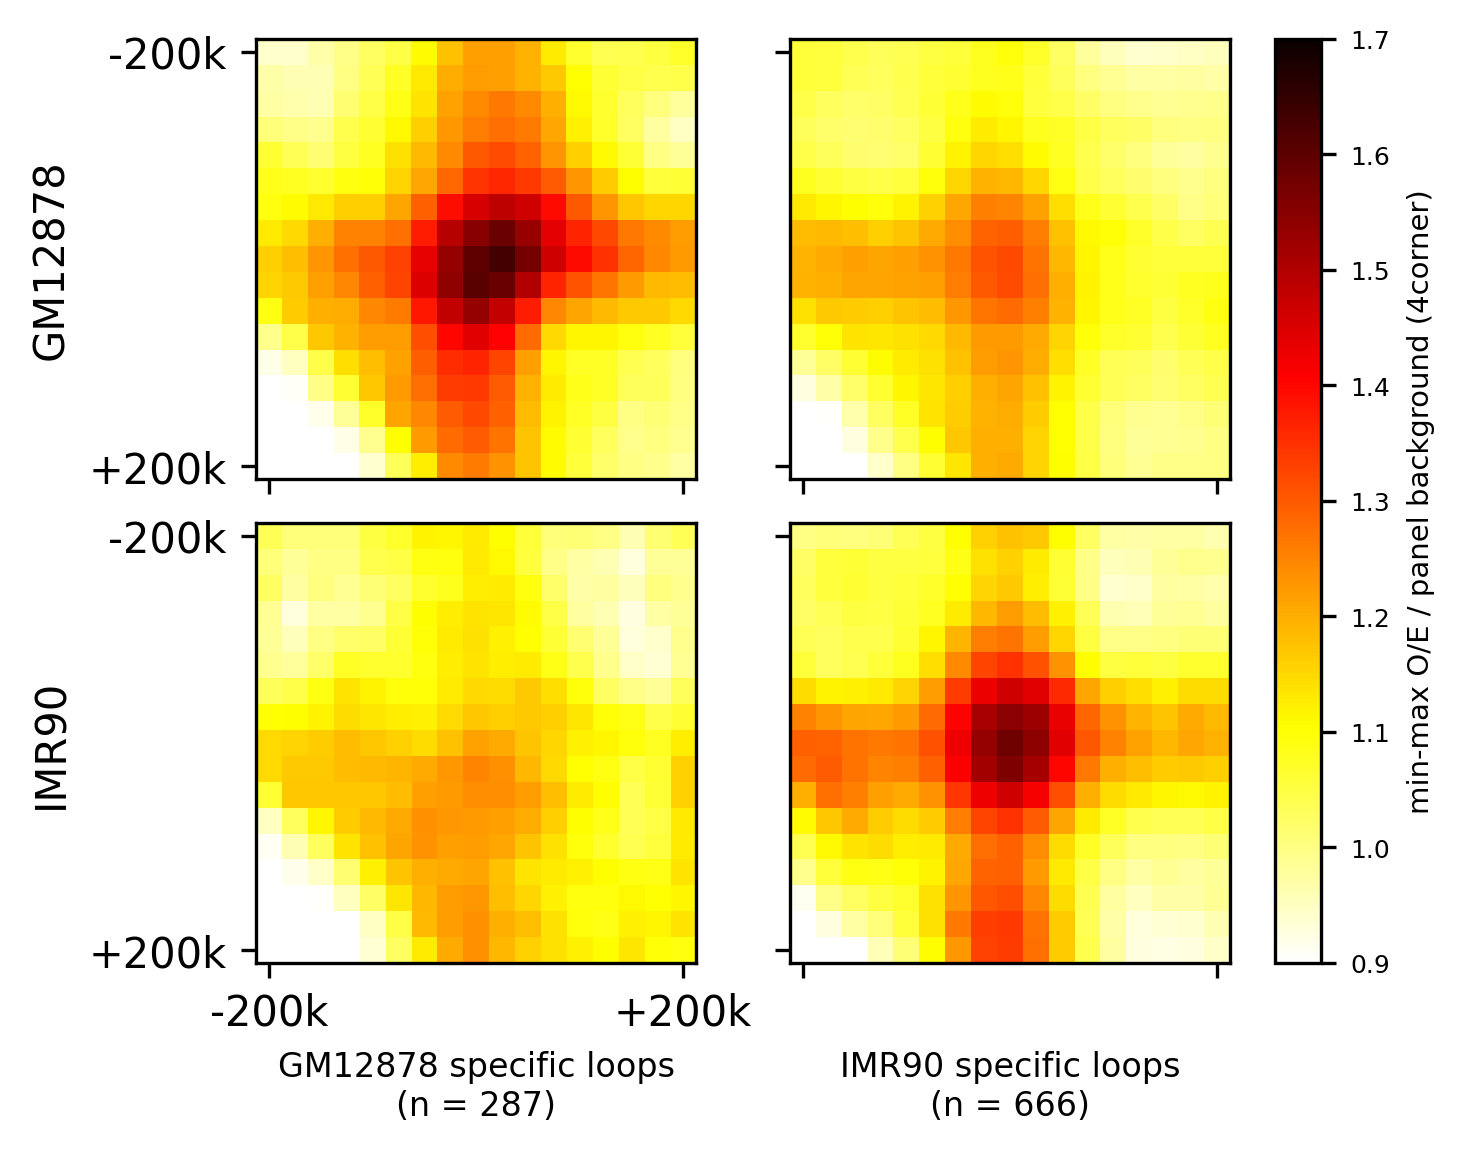

In [7]:
BG_MODE = "4corner"        # "4corner" (recommended) or "lowerleft" (juicer P2LL convention)


def panel_bg(p, mode=BG_MODE, b=BG_WIDTH):
    '''One scalar per panel: the background level to divide it by.'''
    ll = p[-b:, :b].mean()
    if mode == "lowerleft":
        return ll
    if mode == "4corner":
        return np.mean([p[:b, :b].mean(), p[:b, -b:].mean(), ll, p[-b:, -b:].mean()])
    raise ValueError(mode)


vis_bn = np.empty_like(vis_all)
score_bn = np.zeros((n_rows, n_cols))
for i in range(n_rows):
    for j in range(n_cols):
        bg = panel_bg(vis_all[i, j])
        vis_bn[i, j] = vis_all[i, j] / bg
        score_bn[i, j] = vis_all[i, j][apa_flank_bins, apa_flank_bins] / bg

bn_lo, bn_hi = float(np.nanmin(vis_bn)), float(np.nanmax(vis_bn))
print(f"BG_MODE = {BG_MODE}   normalised range {bn_lo:.2f} - {bn_hi:.2f}   (1.0 = panel background)")
print("\ncorner spread per panel (how much the four corners disagree):")
for i in range(n_rows):
    for j in range(n_cols):
        p = vis_all[i, j]; b = BG_WIDTH
        cs = [p[:b, :b].mean(), p[:b, -b:].mean(), p[-b:, :b].mean(), p[-b:, -b:].mean()]
        print(f"  {loop_labels[j].split()[0] + '-loops on ' + celltypes[i]:<28s} "
              f"{(max(cs) - min(cs)) / np.mean(cs):>6.1%}")

fig = draw(vis_bn, score_bn, score_mm, BG_MODE, "vs lower-left",
           f"min-max O/E / panel background ({BG_MODE})",
           vmin=0.9, vmax=float(np.ceil(bn_hi * 10) / 10),
           out_base=f"{FIG_BASE}_bgnorm")
plt.show()

## 5. Difference map -- FINAL FIGURE

The 2xN grid asks the reader to compare panels **across rows** by eye, and that is not
reliable: the two pseudobulks have different within-window value distributions, so an entire
row can sit lighter or darker for reasons that have nothing to do with the loops. (With the
`setdiff` loop sets the GM row's panel mean was 0.351 against IMR's 0.300 -- a visible wash
across every panel in the row.)

This divides instead of asking the eye to. For each loop set, pixel by pixel, it takes
`log2( O/E in GM12878 / O/E in IMR90 )` per loop and then the **median across loops**.

Because it is a ratio of the **same loops** across the two pseudobulks, everything that is a
property of the loop set cancels -- intrinsic loop strength, loop length, and the GM-subsample
enrichment that makes GM-specific loops read high in *both* rows of the raw panel. It is the
visual form of the paired test in section 6.

Expected: a **red** centre for GM-specific loops, a **blue** centre for IMR-specific loops.

saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops_diffmap.png


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops_diffmap.pdf


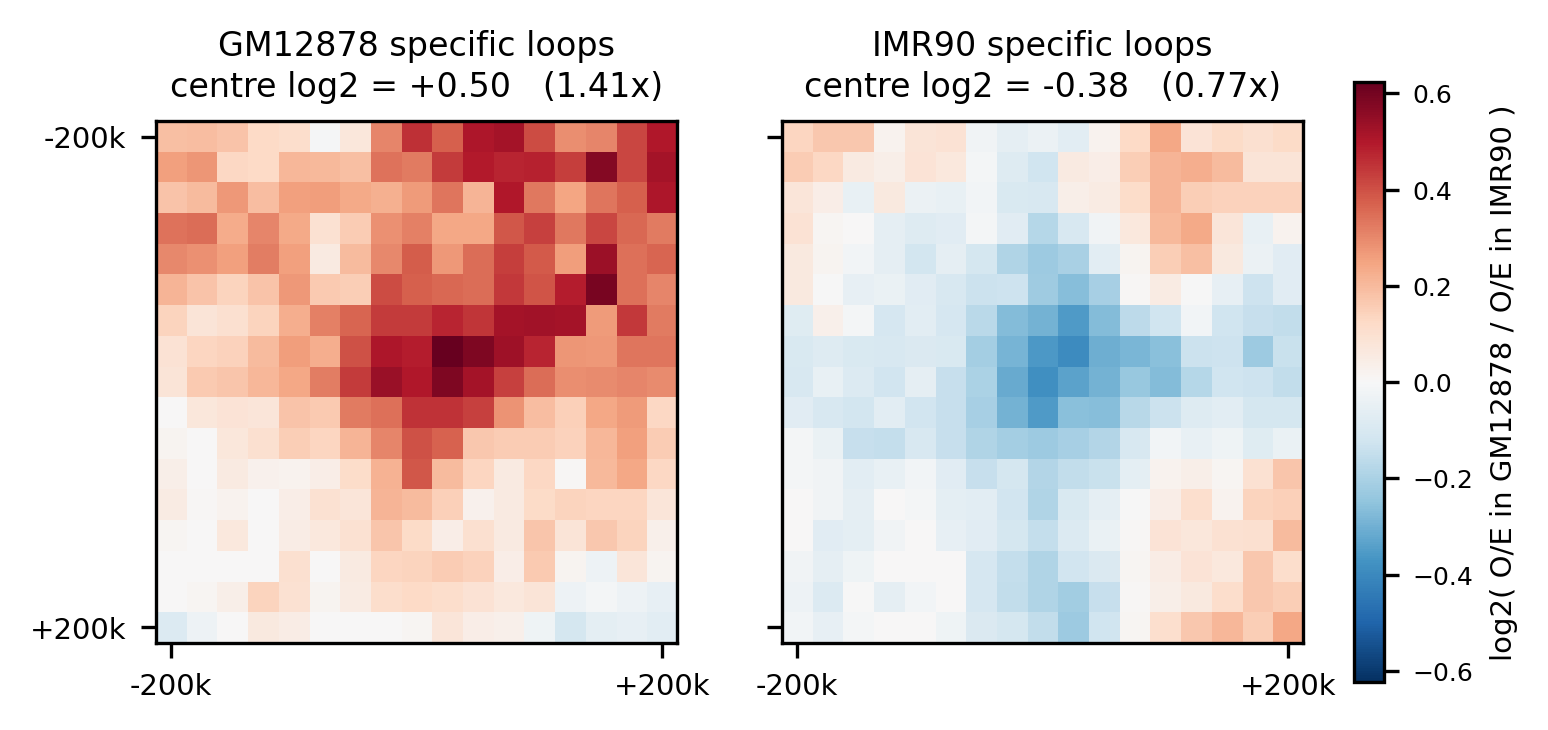


Sign check -- GM-specific should be positive, IMR-specific negative:
  GM12878 specific loops     centre log2 = +0.499   expected +, got +   OK
  IMR90 specific loops       centre log2 = -0.382   expected -, got -   OK


In [8]:
gm_i, imr_i = celltypes.index("GM12878"), celltypes.index("IMR90")

# diffmap is the MEDIAN over loops of the per-loop log2(GM window / IMR window).
# Not log2(mean GM panel / mean IMR panel): a few very strong loops present in both cell
# types dominate the means and wash that ratio toward zero (on the hiccupsdiff GM-specific
# set, +0.055 instead of +0.499 -- a ~9x understatement). The median version below matches
# the paired Mann-Whitney in section 6 exactly, which is the consistency check you want.
diff_maps = [diffmap[j] for j in range(n_cols)]

lim = min(float(np.nanmax(np.abs(diffmap[np.isfinite(diffmap)]))), 1.5)

fig, axes = plt.subplots(1, n_cols, figsize=(n_cols * 2.7, 2.6), dpi=300,
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes)
edge = apa_window_size - 1
lab = f"{apa_flank_bp // 1000}k"

for j, lb in enumerate(loop_labels):
    ax = axes[j]
    im = ax.imshow(diff_maps[j], cmap="RdBu_r", vmin=-lim, vmax=lim)
    c = diff_maps[j][apa_flank_bins, apa_flank_bins]
    ax.set_title(f"{lb}\ncentre log2 = {c:+.2f}   ({2 ** c:.2f}x)", fontsize=8,
                 linespacing=1.3)
    ax.set_xticks([0, edge]); ax.set_xticklabels([f"-{lab}", f"+{lab}"], fontsize=7)
    ax.set_yticks([0, edge]); ax.set_yticklabels([f"-{lab}", f"+{lab}"], fontsize=7)

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.046, pad=0.04)
cbar.set_label("log2( O/E in GM12878 / O/E in IMR90 )", fontsize=7)
cbar.ax.tick_params(labelsize=6)

for ext in ("png", "pdf"):
    p = f"{FIGDIR}/{FIG_BASE}_diffmap.{ext}"
    fig.savefig(p, dpi=300, bbox_inches="tight", transparent=(ext == "pdf"))
    print("saved:", p)
plt.show()

print("\nSign check -- GM-specific should be positive, IMR-specific negative:")
for j, lb in enumerate(loop_labels):
    c = diff_maps[j][apa_flank_bins, apa_flank_bins]
    want = "+" if j == 0 else "-"
    got = "+" if c > 0 else "-"
    print(f"  {lb:<26s} centre log2 = {c:+.3f}   expected {want}, got {got}   "
          f"{'OK' if want == got else '*** UNEXPECTED ***'}")

## 6. The quantitative test

The panels are qualitative. This is the number to quote.

For each loop, take its centre O/E in the GM pseudobulk and in the IMR pseudobulk and form
`log2(GM / IMR)`. Comparing that log-ratio between the two loop sets is an **interaction
test**: because it compares the *same loop* across cell types, it is immune to any property of
the loop set itself -- including the subsample confound described in 4b, loop length, and
anchor strength.

In [9]:
gm_c, imr_c = centres["GM12878"], centres["IMR90"]

ratios, rows = [], []
for j, lb in enumerate(loop_labels):
    a, b = gm_c[j], imr_c[j]
    ok = np.isfinite(a) & np.isfinite(b) & (a > 0) & (b > 0)
    lr = np.log2(a[ok] / b[ok])
    ratios.append(lr)
    rows.append({"loop_set": lb,
                 "n_paired": int(ok.sum()),
                 "median_log2_GM_over_IMR": float(np.median(lr)),
                 "mean_log2_GM_over_IMR": float(np.mean(lr))})

stats = pd.DataFrame(rows)
display(stats.round(4))

u, p = mannwhitneyu(ratios[0], ratios[1], alternative="greater")
delta = np.median(ratios[0]) - np.median(ratios[1])
print(f"Mann-Whitney (GM-specific log-ratio > IMR-specific log-ratio)")
print(f"  U = {u:.4g}   p = {p:.4g}")
print(f"  median separation = {delta:+.4f} log2 units  =  {2**delta:.2f}x")

,loop_set,n_paired,median_log2_GM_over_IMR,mean_log2_GM_over_IMR
0,GM12878 specific loops,285,0.4987,0.6166
1,IMR90 specific loops,665,-0.3817,-0.2464


Mann-Whitney (GM-specific log-ratio > IMR-specific log-ratio)
  U = 1.264e+05   p = 1.491e-16
  median separation = +0.8803 log2 units  =  1.84x


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops_logratio_violin.{png,pdf}


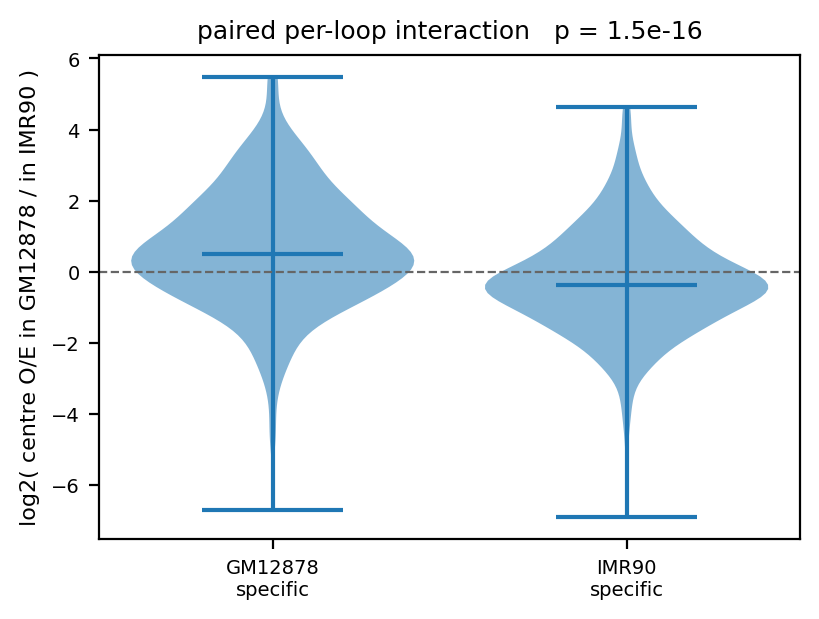

In [10]:
fig, ax = plt.subplots(figsize=(4.2, 3.2), dpi=200)
parts = ax.violinplot(ratios, showmedians=True, widths=0.8)
for pc in parts["bodies"]:
    pc.set_alpha(0.55)
ax.axhline(0, color="0.4", lw=0.8, ls="--")
ax.set_xticks(range(1, len(loop_labels) + 1))
ax.set_xticklabels([lb.replace(" specific loops", "\nspecific") for lb in loop_labels],
                   fontsize=8)
ax.set_ylabel("log2( centre O/E in GM12878 / in IMR90 )", fontsize=8)
ax.set_title(f"paired per-loop interaction   p = {p:.2g}", fontsize=9)
ax.tick_params(labelsize=7)
plt.tight_layout()
for ext in ("png", "pdf"):
    plt.savefig(f"{FIGDIR}/{FIG_BASE}_logratio_violin.{ext}",
                dpi=300, bbox_inches="tight", transparent=(ext == "pdf"))
print(f"saved: {FIGDIR}/{FIG_BASE}_logratio_violin.{{png,pdf}}")
plt.show()

## 7. Write the stats table

In [11]:
stats_out = stats.copy()
stats_out["mannwhitney_U"] = u
stats_out["mannwhitney_p_greater"] = p
for i, ct in enumerate(celltypes):
    for j, lb in enumerate(loop_labels):
        stats_out.loc[stats_out.loop_set == lb, f"apa_minmax_on_{ct}"] = score_mm[i, j]
        stats_out.loc[stats_out.loop_set == lb, f"apa_raw_on_{ct}"] = score_raw[i, j]

path = f"{FIGDIR}/{NPZ_NAME.replace('.npz', '_stats.tsv')}"
stats_out.to_csv(path, sep="\t", index=False)
print("saved:", path)
stats_out.round(4)

saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/apa_insituHCD_stats.tsv


,loop_set,n_paired,median_log2_GM_over_IMR,mean_log2_GM_over_IMR,mannwhitney_U,mannwhitney_p_greater,apa_minmax_on_GM12878,apa_raw_on_GM12878,apa_minmax_on_IMR90,apa_raw_on_IMR90
0,GM12878 specific loops,285,0.4987,0.6166,126442.0,0.0,1.7390,4.1391,1.3155,3.8601
1,IMR90 specific loops,665,-0.3817,-0.2464,126442.0,0.0,1.3598,1.8751,1.5578,1.9663


## Notes

- **Coverage.** The +/-200 kb window cannot hold loops shorter than 200 kb, so
  `step08.load_loopsets()` drops them: GM 2,434 -> 1,734 (680 too close, 20 too far),
  IMR 5,401 -> 4,342 (1,047 too close, 12 too far). A 100 kb flank
  (`apa_flank_bp = 100_000`, `RECOMPUTE = True`) would recover most of them.
- **Not a distance artefact.** GM-specific median separation 550 kb (q25 350, q75 869) vs
  IMR-specific 600 kb (q25 375, q75 975) -- too similar to explain the column effect in 4b.
- **The original figure is untouched.** `APA_2xN_insitu_diffloops.{png,pdf}` (the circular
  version from `loop_insitu_apa.ipynb`) still sits in the same folder for comparison.
- **Provenance.** `apa()` follows the scHiCluster HBA tutorial
  ([03.apa](https://zhoujt1994.github.io/scHiCluster/hba/loop_majortype/03.apa.html)), with
  NaN-safety, an explicit window-shape guard, per-loop centre recording, and all 22 autosomes
  added. See `README.md` -> "Three tracks in this folder".